In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate the repo root, then reuse the EDF/hypnogram readers validated in the EDA step
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts" / "edfx_eda.py").is_file())
sys.path.insert(0, str(ROOT / "scripts"))
from edfx_eda import read_header, read_signals, read_annotations

RAW = ROOT / "data" / "raw" / "sleep-edfx" / "sleep-cassette"   # read-only source
FIG_DIR, TAB_DIR = ROOT / "results" / "figures", ROOT / "results" / "tables"
FIG_DIR.mkdir(exist_ok=True)
TAB_DIR.mkdir(exist_ok=True)

# Fixed pipeline parameters (Ref-1); every later step reads them from here
EPOCH_S = 30        # seconds per epoch
FS = 100            # Hz, EEG/EOG
EMG_FS = 1          # Hz, EMG envelope in SC
TRIM_EPOCHS = 60    # 30 min of Wake kept on each side of the sleep period
IGNORE = -1         # label for epochs excluded from loss and metrics (decision K1)

STAGES = ["Wake", "N1", "N2", "N3", "REM"]
STAGE_COLORS = dict(zip(STAGES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
MUTED, INK, INK_2, SURFACE, GRID = "#898781", "#0b0b0b", "#52514e", "#fcfcfb", "#e1e0d9"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": ["Segoe UI", "DejaVu Sans"], "text.color": INK,
    "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titlelocation": "left", "axes.titleweight": "bold",
    "axes.titlesize": 12, "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})
print("repo root:", ROOT)

repo root: d:\sleep-edfx


In [ ]:
rows = []
for psg in sorted(RAW.glob("*-PSG.edf")):
    hyp = list(RAW.glob(f"{psg.name[:7]}*-Hypnogram.edf"))  # 8th character differs (scorer code)
    assert len(hyp) == 1, psg.name
    rows.append(dict(rec=psg.name[:7], subject=int(psg.name[3:5]), night=int(psg.name[5]),
                     psg=psg, hyp=hyp[0]))
inventory = pd.DataFrame(rows)

nights = inventory.groupby("subject").size()
assert len(inventory) == 153 and inventory["subject"].nunique() == 78
assert set(nights[nights == 1].index) == {13, 36, 52}    # only these subjects have a single night
inventory[["rec", "subject", "night"]].head()

,rec,subject,night
0,SC4001E,0,1
1,SC4002E,0,2
2,SC4011E,1,1
3,SC4012E,1,2
4,SC4021E,2,1


In [3]:
REC = "SC4001E"
item = inventory.set_index("rec").loc[REC]
hdr = read_header(item["psg"])

print(f"{REC}: {hdr['nrec']} data records x {hdr['rec_dur']:g} s = {hdr['duration_s'] / 3600:.2f} h")
pd.DataFrame({"channel": hdr["labels"], "unit": hdr["dims"], "fs_hz": hdr["fs"],
              "prefilter": hdr["prefilter"]})

SC4001E: 2650 data records x 30 s = 22.08 h


,channel,unit,fs_hz,prefilter
0,EEG Fpz-Cz,uV,100.0,HP:0.5Hz LP:100Hz [enhanced cassette BW]
1,EEG Pz-Oz,uV,100.0,HP:0.5Hz LP:100Hz [enhanced cassette BW]
2,EOG horizontal,uV,100.0,HP:0.5Hz LP:100Hz [enhanced cassette BW]
3,Resp oro-nasal,,1.0,HP:0.03Hz LP:0.9Hz
4,EMG submental,uV,1.0,HP:16Hz Rectification LP:0.7Hz
5,Temp rectal,DegC,1.0,
6,Event marker,,1.0,Hold during 2 seconds


In [4]:
CHANNELS = ["EEG Fpz-Cz", "EEG Pz-Oz", "EOG horizontal", "EMG submental"]
sig = read_signals(item["psg"], hdr, set(CHANNELS))   # physical units (uV), float32

pd.DataFrame({
    ch: {"samples": len(x), "seconds": len(x) / hdr["fs"][hdr["labels"].index(ch)],
         "min": x.min(), "median": np.median(x), "max": x.max()}
    for ch, x in sig.items()
}).T.round(1).astype({"samples": int})

,samples,seconds,min,median,max
EEG Fpz-Cz,7950000,79500.0,-192.0,0.4,170.6
EEG Pz-Oz,7950000,79500.0,-171.1,-0.5,196.0
EOG horizontal,7950000,79500.0,-511.8,0.2,517.2
EMG submental,79500,79500.0,-0.1,3.4,3.8


In [5]:
annotations = read_annotations(item["hyp"])     # (onset s, duration s, text)
print(len(annotations), "annotations; first three:")
for a in annotations[:3]:
    print("  ", a)

# R&K stages 3 and 4 merge into N3 (AASM). Movement time and '?' are kept but flagged IGNORE.
STAGE_TO_LABEL = {"Sleep stage W": 0, "Sleep stage 1": 1, "Sleep stage 2": 2,
                  "Sleep stage 3": 3, "Sleep stage 4": 3, "Sleep stage R": 4,
                  "Movement time": IGNORE, "Sleep stage ?": IGNORE}


def hypnogram_to_epochs(annotations, signal_seconds):
    """One label per 30 s epoch, cropped to the signal length."""
    n_epochs = int(signal_seconds // EPOCH_S)
    labels = np.full(n_epochs, IGNORE, dtype=np.int8)    # epochs not covered by the hypnogram stay ignored
    for onset, duration, text in annotations:
        if text in STAGE_TO_LABEL:
            start, stop = int(onset // EPOCH_S), int((onset + duration) // EPOCH_S)
            labels[start:min(stop, n_epochs)] = STAGE_TO_LABEL[text]
    return labels


labels = hypnogram_to_epochs(annotations, hdr["duration_s"])
counts = pd.Series(np.bincount(labels + 1, minlength=6), index=["ignored"] + STAGES)
print(f"{len(labels)} epochs = floor({hdr['duration_s']:g} / {EPOCH_S}); hypnogram ends at "
      f"{max(o + d for o, d, _ in annotations) / 3600:.1f} h, signal at {hdr['duration_s'] / 3600:.1f} h")
counts

154 annotations; first three:
   (0.0, 30630.0, 'Sleep stage W')
   (30630.0, 120.0, 'Sleep stage 1')
   (30750.0, 390.0, 'Sleep stage 2')
2650 epochs = floor(79500 / 30); hypnogram ends at 24.0 h, signal at 22.1 h


ignored       0
Wake       1997
N1           58
N2          250
N3          220
REM         125
dtype: int64

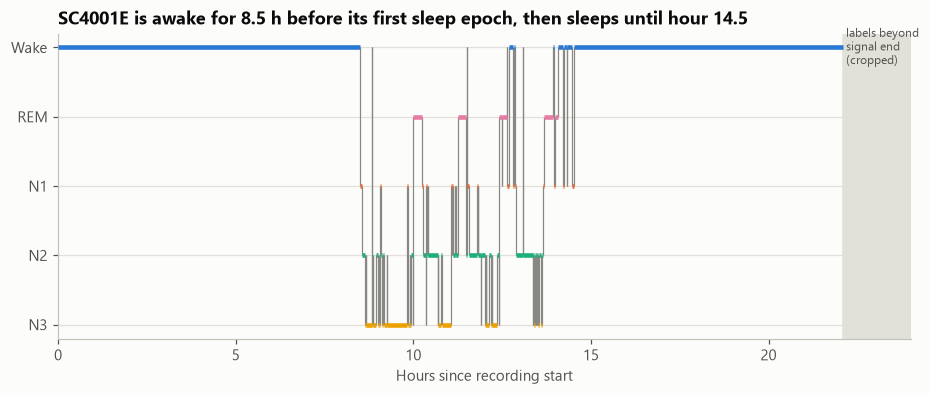

In [6]:
LEVEL = {0: 4, 4: 3, 1: 2, 2: 1, 3: 0}   # conventional hypnogram order, Wake on top, N3 at the bottom
inv_stage = dict(enumerate(STAGES))
change = np.flatnonzero(np.diff(labels)) + 1
starts, stops = np.r_[0, change], np.r_[change, len(labels)]
hours = lambda e: e * EPOCH_S / 3600

fig, ax = plt.subplots(figsize=(10, 3.6))
prev = None
for a, b in zip(starts, stops):
    lab = int(labels[a])
    if lab == IGNORE:
        ax.axvspan(hours(a), hours(b), color=GRID, zorder=0)
        prev = None
        continue
    ax.hlines(LEVEL[lab], hours(a), hours(b), color=STAGE_COLORS[inv_stage[lab]], lw=3, zorder=3)
    if prev is not None:
        ax.vlines(hours(a), LEVEL[prev], LEVEL[lab], color=MUTED, lw=0.8, zorder=2)
    prev = lab
ax.axvspan(hours(len(labels)), 24, color=GRID, zorder=0)
ax.text(hours(len(labels)) + 0.1, 4, "labels beyond\nsignal end\n(cropped)", fontsize=8, color=INK_2, va="center")
sleep_idx = np.flatnonzero((labels >= 1) & (labels <= 4))
ax.set_yticks([4, 3, 2, 1, 0], ["Wake", "REM", "N1", "N2", "N3"])
ax.set_xlim(0, 24)
ax.set_xlabel("Hours since recording start")
ax.set_title(f"{REC} is awake for {hours(sleep_idx[0]):.1f} h before its first sleep epoch, "
             f"then sleeps until hour {hours(sleep_idx[-1]):.1f}")
fig.savefig(FIG_DIR / f"02_hypnogram_{REC}.png")
plt.show()

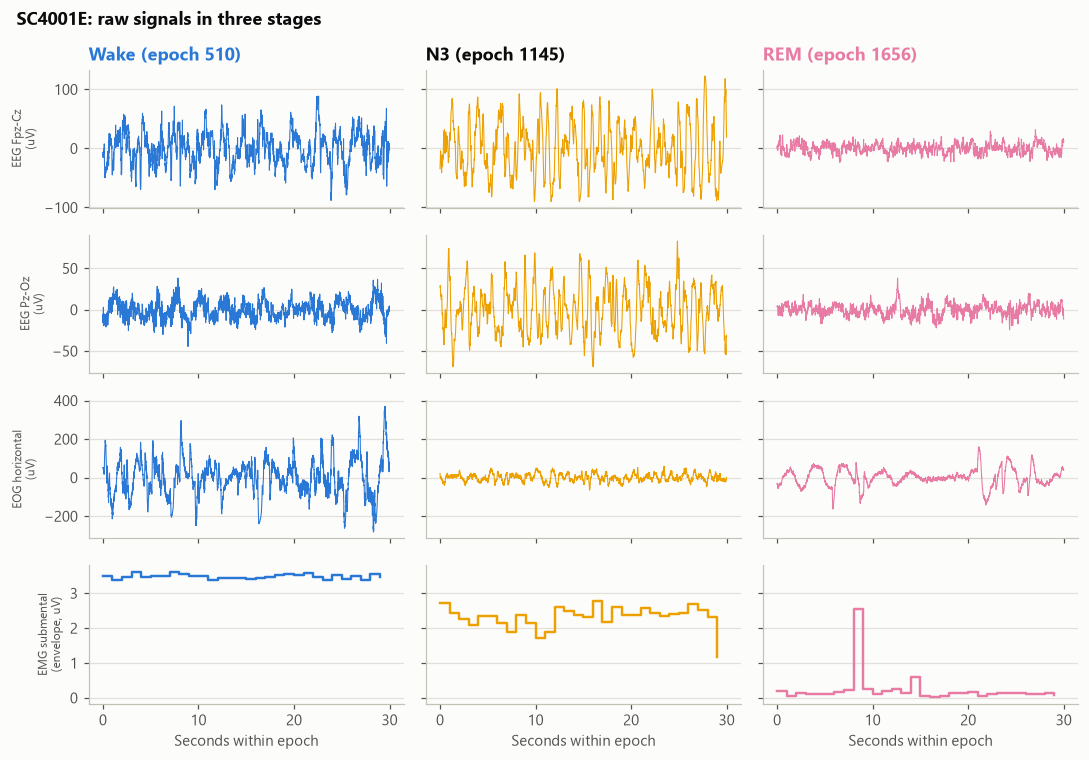

In [7]:
def middle_epoch_of_longest_run(labels, stage):
    """Epoch index at the centre of the longest uninterrupted run of `stage`."""
    mask = np.r_[False, labels == stage, False]
    edges = np.flatnonzero(np.diff(mask.astype(np.int8)))
    s, e = edges[::2], edges[1::2]
    k = np.argmax(e - s)
    return (s[k] + e[k]) // 2


picks = {"Wake": 0, "N3": 3, "REM": 4}
fig, axes = plt.subplots(4, 3, figsize=(10, 7), sharex=True, sharey="row")
for col, (name, code) in enumerate(picks.items()):
    ep = middle_epoch_of_longest_run(labels, code)
    for row, ch in enumerate(CHANNELS):
        fs = hdr["fs"][hdr["labels"].index(ch)]
        x = sig[ch][int(ep * EPOCH_S * fs): int((ep + 1) * EPOCH_S * fs)]
        ax = axes[row, col]
        ax.plot(np.arange(len(x)) / fs, x, lw=0.7 if fs > 1 else 1.6, color=STAGE_COLORS[name],
                drawstyle="default" if fs > 1 else "steps-post")
        if row == 0:
            ax.set_title(f"{name} (epoch {ep})", color=STAGE_COLORS[name] if name != "N3" else INK)
        if col == 0:
            ax.set_ylabel(f"{ch}\n({'uV' if ch != 'EMG submental' else 'envelope, uV'})", fontsize=8)
for ax in axes[-1]:
    ax.set_xlabel("Seconds within epoch")
fig.suptitle(f"{REC}: raw signals in three stages", x=0.02, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / f"02_raw_signals_by_stage_{REC}.png")
plt.show()

In [8]:
with open(ROOT / "results" / "eda" / "eda_records.json", encoding="utf-8") as f:
    eda = {r["rec"]: r for r in json.load(f)}

all_labels = {}
for r in inventory.itertuples():
    h = read_header(r.psg)
    all_labels[r.rec] = hypnogram_to_epochs(read_annotations(r.hyp), h["duration_s"])

for rec, lab in all_labels.items():
    full = eda[rec]["full"]    # EDA counts: [W, N1, N2, N3, REM, Movement time, Unscored]
    assert np.bincount(lab[lab >= 0], minlength=5).tolist() == full[:5], rec
    assert int((lab == IGNORE).sum()) == full[5] + full[6], rec

total = np.bincount(np.concatenate(list(all_labels.values())) + 1, minlength=6)
print(f"{len(all_labels)} recordings, {total.sum():,} epochs; all counts match the EDA")
pd.Series(total, index=["ignored"] + STAGES)

153 recordings, 416,424 epochs; all counts match the EDA


ignored      1463
Wake       285433
N1          21522
N2          69132
N3          13039
REM         25835
dtype: int64